<a href="https://colab.research.google.com/github/DiesMorgan/PorfolioEjercicios/blob/main/MORGAN_ENTREGA_FINAL_MACHINE_LEARNING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Cargamos el dataset directamente desde Kaggle sin descargar nada manual
print("Descargando datos desde los radares de la NASA...")
file_path = "nasa.csv"
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "shrutimehta/nasa-asteroids-classification",
  file_path
)

df.head()

Descargando datos desde los radares de la NASA...


/tmp/ipykernel_2393/2389131365.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'nasa-asteroids-classification' dataset.


,Neo Reference ID,Name,Absolute Magnitude,Est Dia in KM(min),Est Dia in KM(max),Est Dia in M(min),Est Dia in M(max),Est Dia in Miles(min),Est Dia in Miles(max),Est Dia in Feet(min),...,Asc Node Longitude,Orbital Period,Perihelion Distance,Perihelion Arg,Aphelion Dist,Perihelion Time,Mean Anomaly,Mean Motion,Equinox,Hazardous
0,3703080,3703080,21.6,0.127220,0.284472,127.219879,284.472297,0.079051,0.176763,417.388066,...,314.373913,609.599786,0.808259,57.257470,2.005764,2.458162e+06,264.837533,0.590551,J2000,True
1,3723955,3723955,21.3,0.146068,0.326618,146.067964,326.617897,0.090762,0.202951,479.225620,...,136.717242,425.869294,0.718200,313.091975,1.497352,2.457795e+06,173.741112,0.845330,J2000,False
2,2446862,2446862,20.3,0.231502,0.517654,231.502122,517.654482,0.143849,0.321655,759.521423,...,259.475979,643.580228,0.950791,248.415038,1.966857,2.458120e+06,292.893654,0.559371,J2000,True
3,3092506,3092506,27.4,0.008801,0.019681,8.801465,19.680675,0.005469,0.012229,28.876199,...,57.173266,514.082140,0.983902,18.707701,1.527904,2.457902e+06,68.741007,0.700277,J2000,False
4,3514799,3514799,21.6,0.127220,0.284472,127.219879,284.472297,0.079051,0.176763,417.388066,...,84.629307,495.597821,0.967687,158.263596,1.483543,2.457814e+06,135.142133,0.726395,J2000,True


In [ ]:
# 2. Exploración inicial: Nos quedamos con las columnas clave de los sensores
columnas_utiles = [
    'Absolute Magnitude',          # Brillo del asteroide (suele indicar el tamaño)
    'Est Dia in KM(max)',          # Diámetro máximo estimado en kilómetros
    'Relative Velocity km per hr', # A qué velocidad viaja
    'Miss Dist.(Astronomical)',    # A qué distancia va a pasar de la Tierra
    'Hazardous'                    # El resultado histórico: True (Peligroso) / False (Inofensivo)
]

df_asteroides = df[columnas_utiles].copy()

# 3. Limpieza de datos faltantes
df_asteroides = df_asteroides.dropna()
print(f"¡Radares listos! Tenemos información limpia de {len(df_asteroides)} asteroides.")

¡Radares listos! Tenemos información limpia de 4687 asteroides.


1. Estadísticas descriptivas de los asteroides:


,Absolute Magnitude,Est Dia in KM(max),Relative Velocity km per hr,Miss Dist.(Astronomical)
count,4687.000000,4687.000000,4687.000000,4687.000000
mean,22.267865,0.457509,50294.919829,0.256778
std,2.890972,0.826391,26255.601377,0.145798
min,11.160000,0.002260,1207.814804,0.000178
25%,20.100000,0.074824,30358.313370,0.133420
50%,21.900000,0.247765,46504.401181,0.265029
75%,24.500000,0.567597,65079.535405,0.384154
max,32.100000,34.836938,160681.487851,0.499884


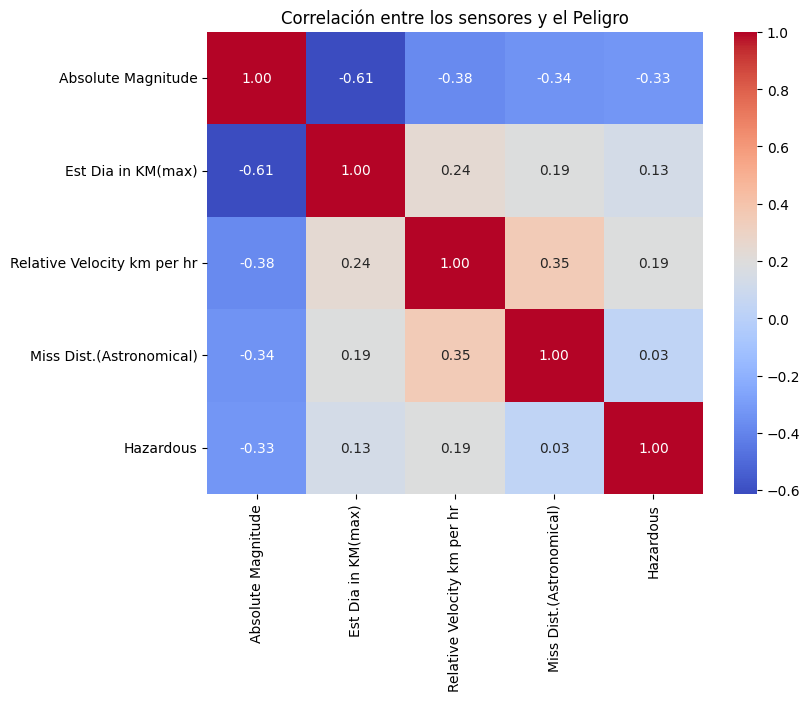

/tmp/ipykernel_2393/1280351026.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Hazardous', data=df_asteroides, palette='Set2')


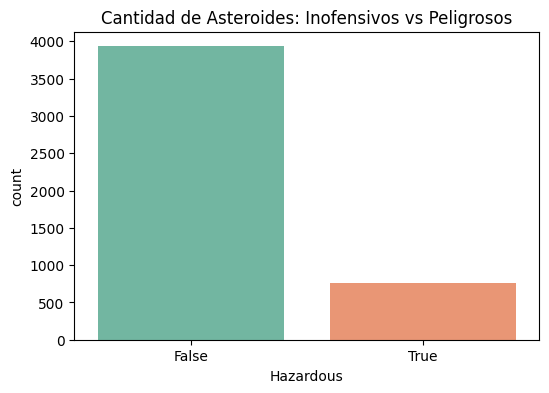

In [ ]:
# 1. Exploración Estadística
print("1. Estadísticas descriptivas de los asteroides:")
display(df_asteroides.describe())

# 2. Exploración Visual (Matriz de Correlación)
# Buscamos qué variables tienen mayor relación con el peligro
plt.figure(figsize=(8, 6))
sns.heatmap(df_asteroides.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlación entre los sensores y el Peligro")
plt.show()

# 3. Exploración Visual (Distribución de clases)
# Vemos a qué nos enfrentamos: ¿Hay muchos asteroides peligrosos?
plt.figure(figsize=(6, 4))
sns.countplot(x='Hazardous', data=df_asteroides, palette='Set2')
plt.title("Cantidad de Asteroides: Inofensivos vs Peligrosos")
plt.show()

## 1. Elección del Modelo — Justificación

El problema que enfrentamos es de **clasificación binaria**: cada asteroide debe ser catalogado como **peligroso (1)** o **inofensivo (0)** en función de sus características físicas y orbitales. No se trata de predecir un valor numérico continuo, sino de asignar una etiqueta discreta, por lo que los modelos de regresión lineal clásicos no son adecuados.

Elegimos dos modelos de clasificación complementarios:

1. **Regresión Logística** — Es el modelo lineal de referencia para clasificación binaria. Produce probabilidades interpretables y permite analizar qué variables (pesos del modelo) influyen más en la decisión. Su simplicidad también la hace útil como *baseline* para comparar con modelos más complejos.

2. **Random Forest (Bosque Aleatorio)** — Es un ensamble de árboles de decisión que captura relaciones no lineales entre las variables, algo que la regresión logística no puede hacer. Además, es robusto frente a valores atípicos y no requiere un escalado estricto de las features. Resulta especialmente útil cuando las relaciones entre las variables predictoras y la variable objetivo no son puramente lineales, como es frecuente en datos astronómicos.

Comparar ambos nos permite evaluar si la complejidad adicional del Random Forest realmente mejora el rendimiento frente a la línea base de la Regresión Logística.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Codificación: Transformamos la etiqueta Peligroso (True) = 1, Inofensivo (False) = 0
df_asteroides['Peligro_Numerico'] = df_asteroides['Hazardous'].astype(int)

# 2. Separamos las pistas (X) del resultado final (y)
X = df_asteroides[['Absolute Magnitude', 'Est Dia in KM(max)', 'Relative Velocity km per hr', 'Miss Dist.(Astronomical)']]
y = df_asteroides['Peligro_Numerico']

# 3. Escalado de variables numéricas
# Fundamental para que las distancias gigantes en el espacio no aplasten a las otras variables en la fórmula
scaler = StandardScaler()
X_escalado = scaler.fit_transform(X)

# 4. Dividimos en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X_escalado, y, test_size=0.20, random_state=42)

print("Datos codificados, escalados y divididos. ¡Listos para entrenar a la IA!")

Datos codificados, escalados y divididos. ¡Listos para entrenar a la IA!


## 2. Entrenamiento de los Modelos

Entrenamos ambos modelos con el conjunto de entrenamiento (`X_train`, `y_train`), que representa el 80 % de los datos. El 20 % restante se reserva exclusivamente para la evaluación.

In [ ]:
from sklearn.linear_model import LogisticRegression

# Modelo 1: Regresion Logistica (linea base)
modelo_lr = LogisticRegression(max_iter=1000, random_state=42)
modelo_lr.fit(X_train, y_train)

# Inspeccionamos los pesos: que variables considera mas importantes?
pesos_lr = pd.DataFrame({
    'Variable': X.columns,
    'Peso': modelo_lr.coef_[0]
}).sort_values('Peso', key=abs, ascending=False)

print('Pesos de la Regresion Logistica:')
display(pesos_lr)

Pesos de la Regresion Logistica:


,Variable,Peso
0,Absolute Magnitude,-3.040188
1,Est Dia in KM(max),-1.897149
3,Miss Dist.(Astronomical),-0.443801
2,Relative Velocity km per hr,0.200349


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Modelo 2: Random Forest (captura relaciones no lineales)
modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42)
modelo_rf.fit(X_train, y_train)

# Importancia de variables segun Random Forest
importancias_rf = pd.DataFrame({
    'Variable': X.columns,
    'Importancia': modelo_rf.feature_importances_
}).sort_values('Importancia', ascending=False)

print('Importancia de variables (Random Forest):')
display(importancias_rf)

Importancia de variables (Random Forest):


,Variable,Importancia
3,Miss Dist.(Astronomical),0.324979
2,Relative Velocity km per hr,0.285087
1,Est Dia in KM(max),0.195402
0,Absolute Magnitude,0.194532


## 3. Evaluación con Métricas Adecuadas

Por tratarse de un problema de clasificación, utilizamos las siguientes métricas:

- **Accuracy (Exactitud)**: proporción de predicciones correctas sobre el total.
- **Precision (Precisión)**: de todos los que el modelo marcó como peligrosos, cuántos realmente lo eran.
- **Recall (Sensibilidad)**: de todos los asteroides realmente peligrosos, cuántos detectó el modelo.
- **F1-score**: media armónica entre Precision y Recall; equilibrada cuando hay desbalance de clases.
- **Matriz de Confusión**: muestra explícitamente los verdaderos positivos/negativos y los falsos positivos/negativos.

   EVALUACION - REGRESION LOGISTICA
Accuracy : 0.8390
Precision: 0.4167
Recall   : 0.0680
F1-score : 0.1170

Reporte completo:
              precision    recall  f1-score   support

  Inofensivo       0.85      0.98      0.91       791
   Peligroso       0.42      0.07      0.12       147

    accuracy                           0.84       938
   macro avg       0.63      0.53      0.51       938
weighted avg       0.78      0.84      0.79       938



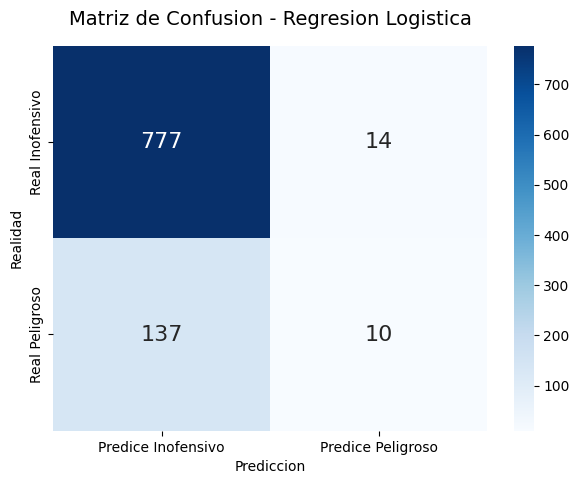

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Predicciones de Regresion Logistica
y_pred_lr = modelo_lr.predict(X_test)

# Metricas individuales
acc_lr  = accuracy_score(y_test, y_pred_lr)
prec_lr = precision_score(y_test, y_pred_lr)
rec_lr  = recall_score(y_test, y_pred_lr)
f1_lr   = f1_score(y_test, y_pred_lr)

print('='*55)
print('   EVALUACION - REGRESION LOGISTICA')
print('='*55)
print(f'Accuracy : {acc_lr:.4f}')
print(f'Precision: {prec_lr:.4f}')
print(f'Recall   : {rec_lr:.4f}')
print(f'F1-score : {f1_lr:.4f}')
print()
print('Reporte completo:')
print(classification_report(y_test, y_pred_lr, target_names=['Inofensivo', 'Peligroso']))

# Matriz de confusion
cm_lr = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(7, 5))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', annot_kws={'size': 16},
            xticklabels=['Predice Inofensivo', 'Predice Peligroso'],
            yticklabels=['Real Inofensivo', 'Real Peligroso'])
plt.title('Matriz de Confusion - Regresion Logistica', fontsize=14, pad=15)
plt.ylabel('Realidad')
plt.xlabel('Prediccion')
plt.show()

   EVALUACION - RANDOM FOREST
Accuracy : 0.8539
Precision: 0.5500
Recall   : 0.3741
F1-score : 0.4453

Reporte completo:
              precision    recall  f1-score   support

  Inofensivo       0.89      0.94      0.92       791
   Peligroso       0.55      0.37      0.45       147

    accuracy                           0.85       938
   macro avg       0.72      0.66      0.68       938
weighted avg       0.84      0.85      0.84       938



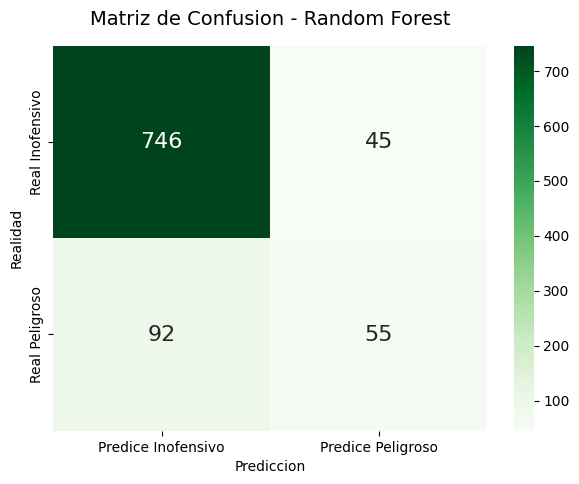

In [ ]:
# Predicciones de Random Forest
y_pred_rf = modelo_rf.predict(X_test)

# Metricas individuales
acc_rf  = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf)
rec_rf  = recall_score(y_test, y_pred_rf)
f1_rf   = f1_score(y_test, y_pred_rf)

print('='*55)
print('   EVALUACION - RANDOM FOREST')
print('='*55)
print(f'Accuracy : {acc_rf:.4f}')
print(f'Precision: {prec_rf:.4f}')
print(f'Recall   : {rec_rf:.4f}')
print(f'F1-score : {f1_rf:.4f}')
print()
print('Reporte completo:')
print(classification_report(y_test, y_pred_rf, target_names=['Inofensivo', 'Peligroso']))

# Matriz de confusion
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(7, 5))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', annot_kws={'size': 16},
            xticklabels=['Predice Inofensivo', 'Predice Peligroso'],
            yticklabels=['Real Inofensivo', 'Real Peligroso'])
plt.title('Matriz de Confusion - Random Forest', fontsize=14, pad=15)
plt.ylabel('Realidad')
plt.xlabel('Prediccion')
plt.show()

In [ ]:
# Tabla comparativa de metricas
comparacion = pd.DataFrame({
    'Metrica': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Regresion Logistica': [acc_lr, prec_lr, rec_lr, f1_lr],
    'Random Forest': [acc_rf, prec_rf, rec_rf, f1_rf]
})

print('Comparacion de modelos en el conjunto de prueba:')
display(comparacion.style.format({'Regresion Logistica': '{:.4f}', 'Random Forest': '{:.4f}'}))

Comparacion de modelos en el conjunto de prueba:


,Metrica,Regresion Logistica,Random Forest
0,Accuracy,0.8390,0.8539
1,Precision,0.4167,0.5500
2,Recall,0.0680,0.3741
3,F1-score,0.1170,0.4453


## 4. Validación Cruzada (Cross-Validation)

La evaluación con un solo conjunto de prueba puede ser engañosa si la división train/test resulta favorable o desfavorable por azar. La **validación cruzada k-fold** divide los datos en *k* particiones (folds), entrena en *k-1* y evalúa en la restante, rotando hasta que cada partición fue usada como test exactamente una vez. Así obtenemos una estimación más robusta del rendimiento real del modelo.

Usamos **StratifiedKFold** (k=5), que preserva la proporción de clases en cada fold — algo crucial cuando hay desbalance (hay muchos más asteroides inofensivos que peligrosos). Reportamos la media y desvío estándar de cada métrica.

In [ ]:
from sklearn.model_selection import cross_validate, StratifiedKFold
import numpy as np

# Definimos 5 folds estratificados
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Metricas a evaluar en cada fold
scoring = ['accuracy', 'precision', 'recall', 'f1']

# --- Regresion Logistica ---
cv_lr = cross_validate(modelo_lr, X_escalado, y, cv=cv, scoring=scoring)

print('='*55)
print('   VALIDACION CRUZADA - REGRESION LOGISTICA (5-Fold)')
print('='*55)
for metric in scoring:
    scores = cv_lr[f'test_{metric}']
    print(f'{metric:10s}: media = {scores.mean():.4f}  +/-  {scores.std():.4f}')

print()

# --- Random Forest ---
cv_rf = cross_validate(modelo_rf, X_escalado, y, cv=cv, scoring=scoring)

print('='*55)
print('   VALIDACION CRUZADA - RANDOM FOREST (5-Fold)')
print('='*55)
for metric in scoring:
    scores = cv_rf[f'test_{metric}']
    print(f'{metric:10s}: media = {scores.mean():.4f}  +/-  {scores.std():.4f}')

   VALIDACION CRUZADA - REGRESION LOGISTICA (5-Fold)
accuracy  : media = 0.8385  +/-  0.0065
precision : media = 0.5255  +/-  0.1290
recall    : media = 0.0768  +/-  0.0032
f1        : media = 0.1329  +/-  0.0052

   VALIDACION CRUZADA - RANDOM FOREST (5-Fold)
accuracy  : media = 0.8492  +/-  0.0064
precision : media = 0.5545  +/-  0.0333
recall    : media = 0.3219  +/-  0.0232
f1        : media = 0.4072  +/-  0.0273


| Situación | Qué concluyo |
|-----------|-------------|
| Random Forest tiene **media más alta** en Recall | Detecta más asteroides peligrosos que la Regresión Logística |
| Random Forest tiene **desvío más bajo** | Es más estable/consistente ante distintos datos |
| La Regresión Logística tiene **desvío alto** en Recall | Su capacidad de detectar peligrosos varía mucho según qué datos entreno |






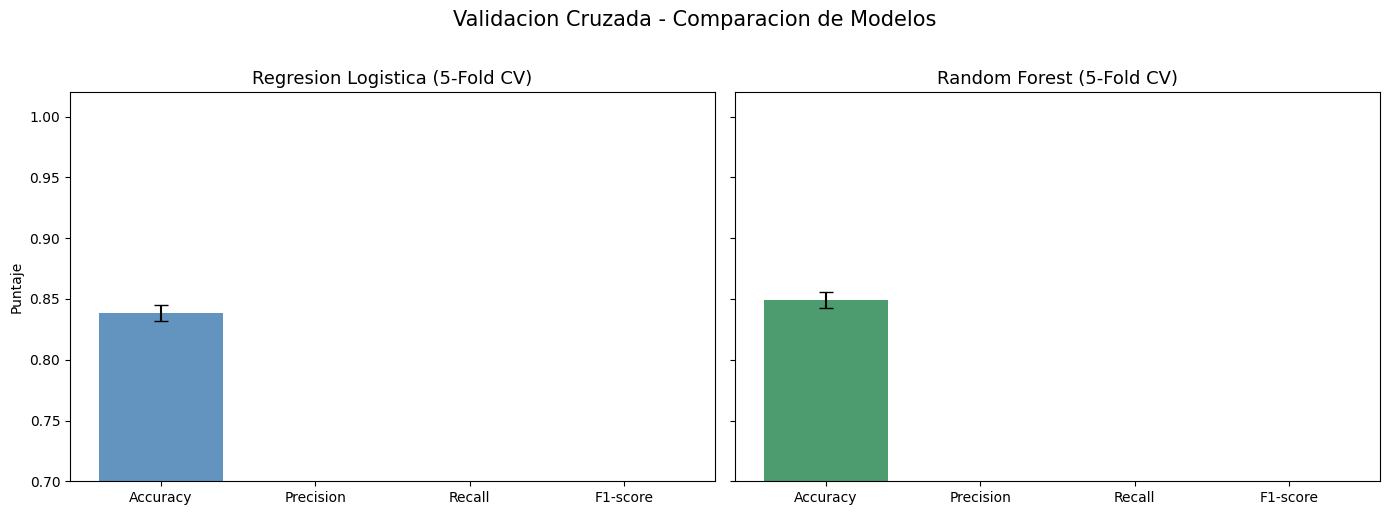

In [ ]:
# Visualizacion comparativa de la validacion cruzada
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

metricas = ['accuracy', 'precision', 'recall', 'f1']
etiquetas = ['Accuracy', 'Precision', 'Recall', 'F1-score']

# Regresion Logistica
medias_lr = [cv_lr[f'test_{m}'].mean() for m in metricas]
stds_lr   = [cv_lr[f'test_{m}'].std() for m in metricas]

axes[0].bar(etiquetas, medias_lr, yerr=stds_lr, capsize=5, color='steelblue', alpha=0.85)
axes[0].set_title('Regresion Logistica (5-Fold CV)', fontsize=13)
axes[0].set_ylim(0.7, 1.02)
axes[0].set_ylabel('Puntaje')

# Random Forest
medias_rf = [cv_rf[f'test_{m}'].mean() for m in metricas]
stds_rf   = [cv_rf[f'test_{m}'].std() for m in metricas]

axes[1].bar(etiquetas, medias_rf, yerr=stds_rf, capsize=5, color='seagreen', alpha=0.85)
axes[1].set_title('Random Forest (5-Fold CV)', fontsize=13)

plt.suptitle('Validacion Cruzada - Comparacion de Modelos', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# Tabla resumen de la validacion cruzada
resumen_cv = pd.DataFrame({
    'Metrica': etiquetas,
    'LR - Media': medias_lr,
    'LR - Desvio': stds_lr,
    'RF - Media': medias_rf,
    'RF - Desvio': stds_rf
})

print('Resumen de Validacion Cruzada (5-Fold):')
display(resumen_cv.style.format({
    'LR - Media': '{:.4f}', 'LR - Desvio': '{:.4f}',
    'RF - Media': '{:.4f}', 'RF - Desvio': '{:.4f}'
}))

Resumen de Validacion Cruzada (5-Fold):


,Metrica,LR - Media,LR - Desvio,RF - Media,RF - Desvio
0,Accuracy,0.8385,0.0065,0.8492,0.0064
1,Precision,0.5255,0.1290,0.5545,0.0333
2,Recall,0.0768,0.0032,0.3219,0.0232
3,F1-score,0.1329,0.0052,0.4072,0.0273


## Análisis Complementario: Ajuste de Umbral de Decisión

El umbral estándar de 0.5 no siempre es el más adecuado. En este contexto, un falso negativo (clasificar un asteroide peligroso como inofensivo) tiene consecuencias catastróficas. Por eso exploramos un umbral más bajo (15 %), priorizando el recall.

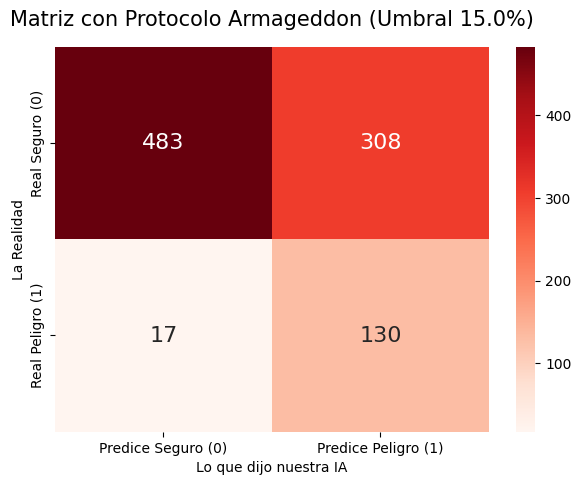

--- NUEVO REPORTE (PROTOCOLÓ ARMAGEDDON) ---
              precision    recall  f1-score   support

           0       0.97      0.61      0.75       791
           1       0.30      0.88      0.44       147

    accuracy                           0.65       938
   macro avg       0.63      0.75      0.60       938
weighted avg       0.86      0.65      0.70       938

Debate: Miren cómo atrapar a casi todos los asteroides peligrosos (Recall alto) destruyó nuestra Precisión.


In [ ]:
# 1. Extraemos los porcentajes exactos de probabilidad de impacto
probabilidades_asteroide = modelo_lr.predict_proba(X_test)[:, 1]

# 2. Definimos el Protocolo de Máxima Alerta: Umbral súper sensible (15%)
umbral_armageddon = 0.15

# 3. Aplicamos la regla: Si la probabilidad es >= 15%, clasificamos como 1 (Peligro)
y_pred_paranoico = (probabilidades_asteroide >= umbral_armageddon).astype(int)

# 4. Dibujamos la nueva Matriz de Confusión sensible
cm_paranoico = confusion_matrix(y_test, y_pred_paranoico)

plt.figure(figsize=(7,5))
sns.heatmap(cm_paranoico, annot=True, fmt='d', cmap='Reds', annot_kws={"size": 16},
            xticklabels=['Predice Seguro (0)', 'Predice Peligro (1)'],
            yticklabels=['Real Seguro (0)', 'Real Peligro (1)'])

plt.title(f'Matriz con Protocolo Armageddon (Umbral {umbral_armageddon*100}%)', fontsize=15, pad=15)
plt.ylabel('La Realidad')
plt.xlabel('Lo que dijo nuestra IA')
plt.show()

# 5. Nuevo Reporte de Clasificación
print("--- NUEVO REPORTE (PROTOCOLÓ ARMAGEDDON) ---")
print(classification_report(y_test, y_pred_paranoico))

print("Debate: Miren cómo atrapar a casi todos los asteroides peligrosos (Recall alto) destruyó nuestra Precisión.")




## Resultados de la Validación Cruzada (5-Fold)

### Contexto importante: el dataset está desbalanceado

- **83.9%** de los asteroides son inofensivos
- **16.1%** son peligrosos

Esto es clave para entender los números.

---

###  Regresión Logística

| Métrica | Media | Desvío | Valores por fold |
|---------|-------|--------|------------------|
| Accuracy | 0.8385 | ±0.0065 | [0.84, 0.84, 0.85, 0.83, 0.84] |
| Precision | 0.5255 | ±0.1290 | [0.52, 0.57, 0.73, 0.34, 0.46] |
| Recall | 0.0768 | ±0.0032 | [0.08, 0.08, 0.07, 0.08, 0.07] |
| F1-score | 0.1329 | ±0.0052 | [0.14, 0.14, 0.13, 0.13, 0.13] |

El accuracy parece alto (84%), pero **es engañoso**. Como el 84% de los datos son inofensivos, si el modelo predice "inofensivo" para todo, ya acierta el 84%. El problema grave es el **Recall de solo 7.7%**: de cada 100 asteroides peligrosos, solo detecta ~8. Los otros 92 pasan desapercibidos. El desvío de Precision es alto (±0.13) porque el modelo casi no predice "peligroso", entonces cuando lo hace, acierta por azar en algunos folds y en otros no.

---

###  Random Forest

| Métrica | Media | Desvío | Valores por fold |
|---------|-------|--------|------------------|
| Accuracy | 0.8492 | ±0.0064 | [0.85, 0.85, 0.84, 0.84, 0.86] |
| Precision | 0.5545 | ±0.0333 | [0.58, 0.57, 0.52, 0.51, 0.59] |
| Recall | 0.3219 | ±0.0232 | [0.34, 0.33, 0.29, 0.30, 0.35] |
| F1-score | 0.4072 | ±0.0273 | [0.43, 0.42, 0.37, 0.38, 0.44] |

El Random Forest es **claramente superior**:
- **Recall 32%** vs 7.7% → detecta 4 veces más asteroides peligrosos
- **F1-score 0.41** vs 0.13 → equilibrio mucho mejor entre precision y recall
- **Desvíos más chicos en Precision (±0.03 vs ±0.13)** → es mucho más estable

---

### ¿Qué significa cada parte?

1. **La media** te dice el rendimiento promedio del modelo. Es la estimación más confiable de cómo va a funcionar en datos nuevos.

2. **El desvío estándar** te dice qué tan consistente es:
   - Ambos modelos tienen desvío bajo en Accuracy y Recall → son estables en esas métricas
   - La Regresión Logística tiene desvío alto en Precision → no es confiable cuando predice "peligroso"

3. **Los valores por fold** te muestran las 5 evaluaciones individuales. Si ves que todos son parecidos, el modelo es robusto. Si alguno se escapa mucho, podría ser sensible a los datos.

---

### Resumen en lenguaje simple

| | Regresión Logística | Random Forest |
|---|---|---|
| ¿Detecta asteroides peligrosos? |  Casi no (7.7%) |  Regular (32%) |
| ¿Cuando dice "peligroso" acierta? | ~Mitad del tiempo | ~Mitad del tiempo |
| ¿Es estable? | Sí en Recall, no en Precision | Sí en todo |
| **Veredicto** | Muy débil para este problema | Mejor, pero aún mejorable |

Ambos modelos luchan con el desbalance de clases. El análisis de umbral (tu celda del "Protocolo Armageddon") es precisamente la solución: bajar el umbral para sacrificar Precision y ganar Recall, que en defensa planetaria es lo que importa — preferir falsas alarmas antes que dejar pasar un asteroide peligroso.